In [32]:
%matplotlib inline
from transformers import AutoTokenizer,AutoConfig
import torch 
import joblib 
import numpy as np
import pandas as pd
import pickle
import os
import re
import glob
import string
from torch.nn import functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from scipy import stats
from tqdm.notebook import tqdm
import sys
from statsmodels.stats import multitest
sys.path.append('..')
from utils import get_segmentation_indices,segmentation_to_word_list,model_to_path_dict

In [33]:
def extract_windows(nperm,event_len,segmentation_indices_in_tokens):
    # windows around boundaries
    window_len = np.min(event_len)
    window_ce_around_boundary = []
    for idx in segmentation_indices_in_tokens[:-1]:
        ce_window = original_ce[idx-window_len:idx+window_len+1]
        window_ce_around_boundary.append(torch.sum(ce_window))
    window_ce_around_boundary = np.array(window_ce_around_boundary)
    
    # random windows
    rng = np.random.default_rng(0)
    choice_range = np.arange(window_len,max(segmentation_indices_in_tokens)-window_len)
    random_indices = rng.choice(choice_range, nperm)
    
    window_ce_random = []
    for idx in random_indices:
        ce_window = original_ce[idx-window_len:idx+window_len+1]
        window_ce_random.append(torch.sum(ce_window))
    window_ce_random = np.array(window_ce_random)
    thresh = np.percentile(window_ce_random,95)
    return window_ce_around_boundary,window_ce_random,thresh

In [34]:
model_name = 'Llama3-8b-instruct'
save_dir = '../../generated'
behavior_data_dir = '../../behavior_data'
model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
model_initial_char = model_to_path_dict[model_name]['initial_char']
tokenizer = AutoTokenizer.from_pretrained(model_to_path_dict[model_name]['hf_name'])

moth_output_dir = os.path.join(save_dir,model_save_dir_name,'moth_stories_output')
original_transcript_dir = os.path.join(behavior_data_dir,'transcripts','moth_stories')
segmentation_dir = os.path.join(behavior_data_dir,'segmentation')

stories = ['pieman','alternateithicatom','odetostepfather','souls','legacy','wheretheressmoke','adventuresinsayingyes','inamoment']
story_to_idx_mapping = {s:stories.index(s)+1 for s in stories}
results_dict = {}
nperm = 1000
results_df = []
for story in stories:
    with open(os.path.join(moth_output_dir,story,'cross_entropy.pkl'),'rb') as f:
        original_ce = pickle.load(f)
    # tokenized txt 
    with open(os.path.join(moth_output_dir,story,'tokenized_txt.pkl'),'rb') as f:
        tokenized_txt = pickle.load(f)
    story_tokens = torch.load(os.path.join(moth_output_dir,story,'tokens.pkl'),map_location=torch.device('cpu'))
    story_tokens = story_tokens[0,1:].cpu().detach()
    consensus_path = os.path.join(segmentation_dir,story,'%s_consensus.txt'%story)
    with open(consensus_path,'r') as f:
        consensus_txt = f.read()
    consensus_txt = consensus_txt.split('\n')
    with open(os.path.join(original_transcript_dir,'%s.txt'%story),'r') as f:
        original_txt = f.read()
    consensus_wordlist = segmentation_to_word_list(consensus_txt)
    segmentation_indices_in_tokens = get_segmentation_indices(tokenized_txt,consensus_wordlist,original_txt,initial_char='Ġ')
    event_len = np.diff([0]+segmentation_indices_in_tokens)
    event_len[0]+=1
    window_ce_around_boundary,window_ce_random,thresh = extract_windows(nperm,event_len,segmentation_indices_in_tokens)
    results_dict[story] = {'window_ce_around_boundary':window_ce_around_boundary,
                          'window_ce_random':window_ce_random,
                          'thresh':thresh}
    values = np.concatenate((window_ce_around_boundary,window_ce_random))
    condition = np.concatenate((np.repeat('boundary',len(window_ce_around_boundary)),np.repeat('random',len(window_ce_random))))
    story_results_df = pd.DataFrame({'window_ce':values,'condition':condition,'story':'Story '+str(story_to_idx_mapping[story])})
    results_df.append(story_results_df)
results_df = pd.concat(results_df,ignore_index = True)

In [35]:
results_dict.keys()

dict_keys(['pieman', 'alternateithicatom', 'odetostepfather', 'souls', 'legacy', 'wheretheressmoke', 'adventuresinsayingyes', 'inamoment'])

In [36]:
def find_sub_list(sl,l):
    sll=len(sl)
    for ind in (i for i,e in enumerate(l) if e==sl[0]):
        if l[ind:ind+sll]==sl:
            return ind,ind+sll
    return None,None

In [37]:
model_name = 'Llama3-8b-instruct'
model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
model_initial_char = model_to_path_dict[model_name]['initial_char']
tokenizer = AutoTokenizer.from_pretrained(model_to_path_dict[model_name]['hf_name'])

moth_output_dir = os.path.join(save_dir,model_save_dir_name,'moth_stories_output')
original_transcript_dir = os.path.join(behavior_data_dir,'transcripts','moth_stories')
segmentation_dir = os.path.join(behavior_data_dir,'segmentation')
timing_dir = os.path.join(behavior_data_dir,'transcripts','timing')
os.makedirs(os.path.join(save_dir,model_save_dir_name,'ce_around_boundary'),exist_ok=True)
stories = ['pieman','alternateithicatom','odetostepfather','souls','legacy','wheretheressmoke','adventuresinsayingyes','inamoment']

# x axis as time 

In [38]:
# num window tokens to the left of boundary, num window tokens to the right of boundary
#window = 14 # this gives 10 words to the left, 10 words to the right
window = 30
story_big_dfs2 ={}
story_segmentation_indices_in_tokens2={}
story_start_end_time ={}
for story in stories:
    with open(os.path.join(moth_output_dir,story,'cross_entropy.pkl'),'rb') as f:
        original_ce = pickle.load(f)
    story_kl = np.load(os.path.join(moth_output_dir,story,'kl.npy'))
    story_kl = story_kl[:-1] 
    story_kl = np.insert(story_kl,0,np.nan)
    # tokenized txt 
    with open(os.path.join(moth_output_dir,story,'tokenized_txt.pkl'),'rb') as f:
        tokenized_txt = pickle.load(f)
    story_tokens = torch.load(os.path.join(moth_output_dir,story,'tokens.pkl'),map_location=torch.device('cpu'))
    story_tokens = story_tokens[0,1:].cpu().detach()
    consensus_path = os.path.join(segmentation_dir,story,'%s_consensus.txt'%story)
    with open(consensus_path,'r') as f:
        consensus_txt = f.read()
    consensus_txt = consensus_txt.split('\n')
    with open(os.path.join(original_transcript_dir,'%s.txt'%story),'r') as f:
        original_txt = f.read()
    consensus_wordlist = segmentation_to_word_list(consensus_txt)
    segmentation_indices_in_tokens = get_segmentation_indices(tokenized_txt,consensus_wordlist,original_txt,initial_char='Ġ')
    event_len = np.diff([0]+segmentation_indices_in_tokens)
    event_len[0]+=1
    filtered_segmentation_indices_in_tokens = segmentation_indices_in_tokens[:-1].copy()
    
    
    timing_df = pd.read_csv(os.path.join(timing_dir,'%s_timing.csv'%story))
    
    if len(timing_df) != len(consensus_wordlist):
        empty_string_idx = []
        for i in range(len(consensus_wordlist)):
            if consensus_wordlist[i] =='':
                #print(i)
                empty_string_idx.append(i)
        for idx in empty_string_idx:
            row = pd.DataFrame({"text": '', "start": np.nan,"stop":np.nan}, index=[idx])
            timing_df = pd.concat([timing_df.iloc[:idx], row, timing_df.iloc[idx:]]).reset_index(drop=True)
    if story =='souls':
        timing_df['text'] = [t[:-1] if t!= '' and t[-1] == ' ' else t for t in timing_df['text']]
    assert len(timing_df) == len(consensus_wordlist)
    timing_word_list = [t if isinstance(t,str) else '' for t in list(timing_df['text'].values)]
    timing_word_list_low = [x.lower() for x in timing_word_list]
    assert ' '.join(timing_word_list).lower() == original_txt
    
    idx_of_boundaries = [i for i,w in enumerate(consensus_wordlist) if '\n' in w]
    num_events = len(consensus_txt)
    start_token_indices = []
    end_token_indices = []
    chunk_txt = []
    timing_word_list_start_indices = []
    timing_word_list_end_indices = []
    word_list_start_idx = 0
    word_list_end_idx = 1
    all_chunk_dfs =[]
    for idx in segmentation_indices_in_tokens[:-1]:
        start_idx = idx-window
        end_idx = idx+window
        # if start_idx or end_idx is out of story range, set to start/end of story
        if start_idx<0:
            start_idx =0
        if end_idx>original_ce.shape[0]:
            end_idx = original_ce.shape[0]
        # make sure start_idx and end_idx correspond to word start/end
        if start_idx!=0:
            while model_initial_char not in tokenized_txt[start_idx]:
                start_idx-=1
        if end_idx<len(tokenized_txt):
            while model_initial_char not in tokenized_txt[end_idx]:
                end_idx+=1
        this_chunk_txt = tokenizer.decode(story_tokens[start_idx:end_idx])
        if this_chunk_txt not in original_txt:
            this_chunk_txt = ''.join([s.replace(model_initial_char,' ') for s in tokenized_txt[start_idx:end_idx]]) 
            if this_chunk_txt not in original_txt:
                print(this_chunk_txt)
        assert this_chunk_txt in original_txt
        start_token_indices.append(start_idx)
        end_token_indices.append(end_idx)
        chunk_txt.append(this_chunk_txt)
        
        # match word to tokens
        word_list = []
        token_indices = []
        for i,t in enumerate(tokenized_txt[start_idx:end_idx]):
            if model_initial_char in t or i==0:
                word = t.replace(model_initial_char,' ')
                word_list.append(word)
                token_indices.append([start_idx+i])
            else:
                word_list[-1]+=t
                token_indices[-1].extend([start_idx+i])
        word_ce = np.array([torch.sum(original_ce[i]) for i in token_indices]) # sum of all tokens in the word
        word_kl = np.array([np.sum(story_kl[i]) for i in token_indices])
                
        joined_text = ' '.join(timing_word_list[word_list_start_idx:word_list_end_idx]).lower()
        if len(joined_text)>0 and joined_text[0] == ' ':
            joined_text = joined_text[1:]
        if this_chunk_txt[0] == ' ':
            this_chunk_txt = this_chunk_txt[1:]
#         if this_chunk_txt[-1] == ' ':
#             this_chunk_txt = this_chunk_txt[:-1]
        this_chunk_txt_list = this_chunk_txt.lower().split(' ')
        word_list_start_idx,word_list_end_idx = find_sub_list(this_chunk_txt_list,timing_word_list_low)

        assert word_list_start_idx is not None
        timing_word_list_start_indices.append(word_list_start_idx)
        timing_word_list_end_indices.append(word_list_end_idx)
        chunk_timings = timing_df.iloc[word_list_start_idx:word_list_end_idx]
        assert len(chunk_timings)==len(word_list)
        df = pd.DataFrame({'word':word_list,'token_indices':token_indices,'word_ce':word_ce,'word_kl':word_kl})
        big_df = pd.concat([df.reset_index(drop=True), chunk_timings.reset_index(drop=True)],axis = 1)
        if story=='pieman':
            big_df['start'] = big_df['start']/1000
            big_df['stop'] = big_df['stop']/1000
        all_chunk_dfs.append(big_df)
    story_big_dfs2[story]=all_chunk_dfs
    story_segmentation_indices_in_tokens2[story] = segmentation_indices_in_tokens[:-1]
    story_start_end_time[story] = np.array([timing_df.iloc[0]['start'],timing_df.iloc[len(timing_df)-1]['stop']])
    if story=='pieman':
        story_start_end_time[story]/=1000

In [39]:
include_if_midpoint = True # if true, count word to be in the bin if the midpoint is in the bin. Else count word if any part of it is in the bin 
bin_duration = 0.5 #s
seconds = 5
num_bins = int(seconds/bin_duration) # on each side 
story_plot_arrays_info_rate2 = {}
story_plot_arrays_speech_rate2 = {}
story_plot_arrays_surprisal2 = {}
story_plot_arrays_kl2 = {}
for story in story_big_dfs2.keys():
    segmentation_indices_in_tokens = story_segmentation_indices_in_tokens2[story] # this already doesn't have the index of the end of story
    this_story_start_end = story_start_end_time[story]
    all_chunk_dfs = story_big_dfs2[story]
    plot_arrays_info_rate = np.ones((len(segmentation_indices_in_tokens),num_bins*2+1))*np.nan
    plot_arrays_speech_rate = np.ones((len(segmentation_indices_in_tokens),num_bins*2+1))*np.nan
    plot_arrays_surprisal = np.ones((len(segmentation_indices_in_tokens),num_bins*2+1))*np.nan
    plot_arrays_kl = np.ones((len(segmentation_indices_in_tokens),num_bins*2+1))*np.nan
    for i,seg_idx in enumerate(segmentation_indices_in_tokens):
        big_df = all_chunk_dfs[i]
        
        # find where the segmentation point is 
        seg_idx_in_big_df= -1
        for df_idx,row in big_df.iterrows():
            if seg_idx in row['token_indices']:
                seg_idx_in_big_df=df_idx
                break
        assert seg_idx_in_big_df!= -1
        # segmentation time has to be the mid point between two events, otherwise one bin is guaranteed to get a word 
        segmentation_time = (big_df['stop'].iloc[seg_idx_in_big_df]+big_df['start'].iloc[seg_idx_in_big_df+1])/2 # midpoint between end of last event and start of the next, this will be the center of the middle bin
        
        # the end of the middle bin is the segmentation time
        range_start = segmentation_time-(num_bins+1)*bin_duration
        range_end = segmentation_time+(num_bins)*bin_duration
        bin_edges = np.linspace(range_start,range_end,num_bins*2+1+1) # num_bins*2+1+1 because linspace gives that many numbers, and we need num_bins*2+1 intervals
        # if an edge is smaller than story start time or later than story end time, throw out the bin 
        bin_edges = [edge if edge>=this_story_start_end[0] and edge<=this_story_start_end[1] else np.nan for edge in bin_edges]
        bin_edges_start = bin_edges[:-1]
        bin_edges_end = bin_edges[1:]
        
        new_stop =big_df['stop'].values.copy()
        word_mid_point = (new_stop+big_df['start'].values)/2

        for bin_idx,(bin_start,bin_end) in enumerate(zip(bin_edges_start,bin_edges_end)):
            word_indices_in_bin=[]
            if np.isnan(bin_start):
                continue
            if include_if_midpoint:
                word_indices_in_bin = [idx for idx,timing in enumerate(word_mid_point) if timing>=bin_start and timing<=bin_end]
            else:
                for row_idx,row in big_df.iterrows():
                    if row['start']<bin_start and row['stop']>bin_start:
                        word_indices_in_bin.append(row_idx)
                    elif row['start']<bin_end and row['stop']>bin_end:
                        word_indices_in_bin.append(row_idx)
                    elif row['start']>bin_start and row['stop']<bin_end:
                        word_indices_in_bin.append(row_idx)
#             if len(word_indices_in_bin)==0:
#                 print(seg_idx,bin_start,bin_end)
                
            #print(word_indices_in_bin)
            speech_rate = len(word_indices_in_bin)/bin_duration
            bin_ce = np.sum(big_df.iloc[word_indices_in_bin]['word_ce'])
            info_rate = bin_ce/bin_duration
            surprisal = np.mean(big_df.iloc[word_indices_in_bin]['word_ce']) # when there are no words in this bin, surprisal and kl will be nan
            kl = np.mean(big_df.iloc[word_indices_in_bin]['word_kl'])
            plot_arrays_speech_rate[i,bin_idx]=speech_rate
            plot_arrays_info_rate[i,bin_idx] = info_rate
            plot_arrays_surprisal[i,bin_idx] = surprisal
            plot_arrays_kl[i,bin_idx] = kl
#             if len(word_indices_in_bin)==0:
#                 print(story,bin_start,bin_end)
#                 print(big_df.iloc[word_indices_in_bin]['word_ce'])
#                 print(surprisal,kl)

    story_plot_arrays_info_rate2[story]=plot_arrays_info_rate
    story_plot_arrays_speech_rate2[story]=plot_arrays_speech_rate
    story_plot_arrays_surprisal2[story] = plot_arrays_surprisal
    story_plot_arrays_kl2[story] = plot_arrays_kl

## average across stories, plot standard error

In [40]:
colors = sns.color_palette("Spectral", 5)
fontsize = 9

In [41]:
def get_significance(p_val):
    if p_val < 0.001:
        return "***"
    elif p_val < 0.01:
        return "**"
    elif p_val < 0.05:
        return "*"
    else:
        return ""
    

### Compare pre-boundary and post-boundary bins to the boundary bin (LME)

In [42]:
import statsmodels.formula.api as smf
def make_lme_boundary_df(boundary_dict,num_bins,cutoff = 0):
    '''
    Create a DataFrame for mixed-effects modeling of boundary effects, storing mean values of the pre-boundary bins, boundary bin, and the post-boundary bins

    num_bins: number of bins on each side
    cutoff: if 0, include all pre/post bins. If >0, include only the #cutoff pre-bins and #cutoff post-bins'''
    data = []
    for i,story in enumerate(boundary_dict.keys()):
        middle_bin = boundary_dict[story][:,num_bins]
        if cutoff!=0: # number of pre/post bins to include
            pre_boundary = boundary_dict[story][:,num_bins-cutoff:num_bins]
            post_boundary = boundary_dict[story][:,num_bins+1:num_bins+cutoff+1]
        else:
            pre_boundary = boundary_dict[story][:,:num_bins]
            post_boundary = boundary_dict[story][:,num_bins+1:]
        pre_boundary_mean = np.nanmean(pre_boundary,axis = 1)
        post_boundary_mean = np.nanmean(post_boundary,axis =1)
        for idx,v in enumerate(pre_boundary_mean):
            data.append([story, "pre", v,"%s_pair_%d"%(story,idx)])
            #data.append([story, "pre", v,idx])
        for idx,v in enumerate(post_boundary_mean):
            data.append([story, "post", v,"%s_pair_%d"%(story,idx)])
            #data.append([story, "post", v,idx])
        for idx,v in enumerate(middle_bin):
            data.append([story, "boundary", v,"%s_pair_%d"%(story,idx)])
            #data.append([story, "boundary", v,idx])
    df = pd.DataFrame(data, columns=["story","condition","value","boundary_idx"])
    return df

In [43]:
def make_lme_boundary_df2(boundary_dict,num_bins):
    '''
    Create a DataFrame for mixed-effects modeling of boundary effects, storing values of the first bin, boundary bin, and the last bin
    num_bins: number of bins on each side
    '''
    data = []
    for i,story in enumerate(boundary_dict.keys()):
        middle_bin = boundary_dict[story][:,num_bins]
        first_bin = boundary_dict[story][:,0]
        last_bin = boundary_dict[story][:,-1]
        for idx,v in enumerate(first_bin):
            data.append([story, "first", v,"%s_pair_%d"%(story,idx)])
        for idx,v in enumerate(last_bin):
            data.append([story, "last", v,"%s_pair_%d"%(story,idx)])
        for idx,v in enumerate(middle_bin):
            data.append([story, "boundary", v,"%s_pair_%d"%(story,idx)])
    df = pd.DataFrame(data, columns=["story","condition","value","boundary_idx"])
    return df

In [44]:
def plot_boundary_comparison(plot_array, xlabel, ylabel, title, color, savepath=None):
    """
    Fit pre/boundary/post LME comparisons and plot the time course.
    savepath: if not None, save the figure to this path
    """

    # ------------------------------------------------------------
    # LME: pre vs boundary and post vs boundary
    # ------------------------------------------------------------

    lme_df = make_lme_boundary_df(
        plot_array,
        num_bins,
        cutoff=0
    )

    lme_df_wide = lme_df.pivot(
        index='boundary_idx',
        columns='condition',
        values='value'
    )

    lme_df_wide_clean = lme_df_wide.dropna()

    lme_df_clean = lme_df_wide_clean.reset_index().melt(
        id_vars='boundary_idx',
        value_vars=['boundary', 'pre', 'post'],
        var_name='condition',
        value_name='value'
    )

    # make boundary the reference condition
    lme_df_clean['condition'] = pd.Categorical(
        lme_df_clean['condition'],
        categories=['boundary', 'pre', 'post'],
        ordered=True
    )

    # story ID
    lme_df_clean['story'] = (
        lme_df_clean['boundary_idx']
        .str.split('_')
        .str[0]
    )

    model = smf.mixedlm(
        "value ~ condition",
        lme_df_clean,
        groups=lme_df_clean["boundary_idx"],
        vc_formula={"story": "0 + C(story)"}
    ).fit(reml=True)

    print(model.summary())


    # ------------------------------------------------------------
    # P-values
    # ------------------------------------------------------------

    p_pre = model.pvalues['condition[T.pre]']
    p_post = model.pvalues['condition[T.post]']

    pvals_corrected = multitest.multipletests(
        [p_pre, p_post],
        method='fdr_bh'
    )[1]

    sig_pre = get_significance(pvals_corrected[0])
    sig_post = get_significance(pvals_corrected[1])

    print(
        'pre vs boundary:',
        p_pre,
        'corrected:',
        pvals_corrected[0]
    )

    print(
        'post vs boundary:',
        p_post,
        'corrected:',
        pvals_corrected[1]
    )

    n_significant = (
        int(sig_pre != '') +
        int(sig_post != '')
    )


    # ------------------------------------------------------------
    # Mean and SEM across all boundaries/stories
    # ------------------------------------------------------------

    all_plot_arrays = np.concatenate([
        plot_array[story]
        for story in plot_array.keys()
    ])

    nanmean = np.nanmean(
        all_plot_arrays,
        axis=0
    )

    good_count = np.sum(
        ~np.isnan(all_plot_arrays),
        axis=0
    )

    yerr = (
        np.nanstd(all_plot_arrays, axis=0)
        / np.sqrt(good_count)
    )


    # ------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(2.3, 1.4)
    )

    xx = np.linspace(
        -bin_duration * num_bins,
        bin_duration * num_bins,
        num_bins * 2 + 1
    )

    ax.plot(
        xx,
        nanmean,
        color=color
    )

    ax.fill_between(
        xx,
        nanmean - yerr,
        nanmean + yerr,
        alpha=0.3,
        color=color
    )


    # ------------------------------------------------------------
    # Data range
    # ------------------------------------------------------------

    data_min = np.nanmin(
        nanmean - yerr
    )

    data_max = np.nanmax(
        nanmean + yerr
    )

    data_range = (
        data_max - data_min
    )

    if data_range == 0:
        data_range = max(
            abs(data_max),
            1
        )


    # ------------------------------------------------------------
    # Gray bars / boundary square
    # ------------------------------------------------------------

    # Position depends on how much significance annotation
    # needs to appear above the data.
    if n_significant == 2:
        comparison_y = (
            data_max +
            0.10 * data_range
        )

    elif n_significant == 1:
        comparison_y = (
            data_max +
            0.22 * data_range
        )

    else:
        comparison_y = (
            data_max +
            0.35 * data_range
        )

    bar_gap = 0.5
    comparison_color = '0.6'

    # pre average: [-5, 0)
    ax.plot(
        [-5, -bar_gap],
        [comparison_y, comparison_y],
        color=comparison_color,
        linewidth=2.2,
        solid_capstyle='butt'
    )

    # post average: (0, 5]
    ax.plot(
        [bar_gap, 5],
        [comparison_y, comparison_y],
        color=comparison_color,
        linewidth=2.2,
        solid_capstyle='butt'
    )

    # boundary: single point at t=0
    ax.plot(
        0,
        comparison_y,
        marker='s',
        markersize=4,
        color=comparison_color,
        linestyle='None'
    )


    # ------------------------------------------------------------
    # Significance brackets
    # ------------------------------------------------------------

    def add_sig_bracket(
        ax,
        x1,
        x2,
        y,
        sig,
        h
    ):
        ax.plot(
            [x1, x1, x2, x2],
            [y, y + h, y + h, y],
            color='black',
            linewidth=0.8
        )

        ax.text(
            (x1 + x2) / 2,
            y + h,
            sig,
            ha='center',
            va='bottom',
            fontsize=9
        )


    bracket_h = (
        0.05 * data_range
    )

    bracket_gap = (
        0.10 * data_range
    )

    bracket_spacing = (
        0.18 * data_range
    )

    pre_center = -2.5
    post_center = 2.5

    bracket_y1 = (
        comparison_y +
        bracket_gap
    )

    bracket_y2 = (
        bracket_y1 +
        bracket_spacing
    )


    # If both are significant, stagger the two brackets.
    if n_significant == 2:

        add_sig_bracket(
            ax,
            pre_center,
            0,
            bracket_y1,
            sig_pre,
            h=bracket_h
        )

        add_sig_bracket(
            ax,
            0,
            post_center,
            bracket_y2,
            sig_post,
            h=bracket_h
        )


    # If only one is significant, use the lower bracket position.
    elif n_significant == 1:

        if sig_pre != '':
            add_sig_bracket(
                ax,
                pre_center,
                0,
                bracket_y1,
                sig_pre,
                h=bracket_h
            )

        if sig_post != '':
            add_sig_bracket(
                ax,
                0,
                post_center,
                bracket_y1,
                sig_post,
                h=bracket_h
            )


    # ------------------------------------------------------------
    # Adaptive y limits
    # ------------------------------------------------------------

    if n_significant == 2:

        # Existing spacing for plots with two brackets
        ymax = (
            bracket_y2 +
            bracket_h +
            0.12 * data_range
        )

        ymin = (
            data_min -
            0.08 * data_range
        )


    elif n_significant == 1:

        # Wider y-range so a single significance bracket
        # doesn't make the time course look overly stretched.
        ymin = (
            data_min -
            0.45 * data_range
        )

        ymax = (
            bracket_y1 +
            bracket_h +
            0.30 * data_range
        )


    else:

        # Wider range for plots without significance brackets.
        ymin = (
            data_min -
            0.65 * data_range
        )

        ymax = (
            comparison_y +
            0.45 * data_range
        )


    ax.set_ylim(
        ymin,
        ymax
    )


    # ------------------------------------------------------------
    # Boundary line
    # ------------------------------------------------------------

    ylim_range = (
        ymax - ymin
    )

    # slight gap from bottom axis
    vline_ymin = (
        ymin +
        0.04 * ylim_range
    )

    # stop just below the gray boundary square
    vline_ymax = (
        comparison_y -
        0.06 * ylim_range
    )

    ax.vlines(
        x=0,
        ymin=vline_ymin,
        ymax=vline_ymax,
        linestyles='dashed',
        color='black',
        linewidth=1.5
    )


    # ------------------------------------------------------------
    # Labels / formatting
    # ------------------------------------------------------------

    ax.set_xlabel(
        xlabel,
        fontsize=fontsize
    )

    ax.set_ylabel(
        ylabel,
        fontsize=fontsize
    )

    ax.set_title(
        title,
        fontsize=fontsize
    )

    sns.despine()

    if savepath is not None:
        fig.savefig(
            savepath,
            transparent=True
        )

    return model, fig, ax

           Mixed Linear Model Regression Results
Model:              MixedLM  Dependent Variable:  value    
No. Observations:   438      Method:              REML     
No. Groups:         146      Scale:               1.1033   
Min. group size:    3        Log-Likelihood:      -685.0999
Max. group size:    3        Converged:           Yes      
Mean group size:    3.0                                    
-----------------------------------------------------------
                  Coef. Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------
Intercept         1.384    0.097 14.307 0.000  1.194  1.573
condition[T.pre]  1.186    0.123  9.650 0.000  0.945  1.427
condition[T.post] 1.149    0.123  9.349 0.000  0.908  1.390
story Var         0.262    0.086                           

pre vs boundary: 4.935855387798136e-22 corrected: 9.871710775596272e-22
post vs boundary: 8.87107409386244e-21 corrected: 8.87107409386244e-21


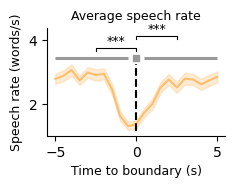

In [45]:
model, fig, ax = plot_boundary_comparison(
    plot_array=story_plot_arrays_speech_rate2,
    xlabel='Time to boundary (s)',
    ylabel='Speech rate (words/s)',
    title='Average speech rate',
    color = colors[1],
    savepath=None,  # os.path.join(save_dir, model_save_dir_name, 'ce_around_boundary', 'speech_rate_by_time_sig_to_boundary.svg')
)

           Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable:  value     
No. Observations:  438      Method:              REML      
No. Groups:        146      Scale:               43.2059   
Min. group size:   3        Log-Likelihood:      -1467.6153
Max. group size:   3        Converged:           Yes       
Mean group size:   3.0                                     
-----------------------------------------------------------
                  Coef. Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------
Intercept         6.848    0.578 11.845 0.000  5.715  7.981
condition[T.pre]  3.496    0.769  4.544 0.000  1.988  5.003
condition[T.post] 3.889    0.769  5.055 0.000  2.381  5.397
story Var         5.597    0.438                           

pre vs boundary: 5.5261065620993555e-06 corrected: 5.5261065620993555e-06
post vs boundary: 4.3027217686518323e-07 corrected: 8.605443537303665e-07


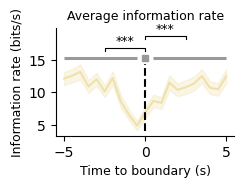

In [46]:
model, fig, ax = plot_boundary_comparison(
    plot_array=story_plot_arrays_info_rate2,
    xlabel='Time to boundary (s)',
    ylabel='Information rate (bits/s)',
    title='Average information rate',
    color = '#efe1aaff',
    savepath=None,  # os.path.join(save_dir, model_save_dir_name, 'ce_around_boundary', 'info_rate_by_time_sig_to_boundary.svg')
)

           Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  value    
No. Observations:    228      Method:              REML     
No. Groups:          76       Scale:               6.2258   
Min. group size:     3        Log-Likelihood:      -540.7651
Max. group size:     3        Converged:           Yes      
Mean group size:     3.0                                    
------------------------------------------------------------
                  Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------
Intercept          5.073    0.299 16.948 0.000  4.486  5.659
condition[T.pre]  -0.811    0.405 -2.003 0.045 -1.604 -0.017
condition[T.post] -0.664    0.405 -1.640 0.101 -1.457  0.130
story Var          0.583    0.213                           

pre vs boundary: 0.04519690579805403 corrected: 0.09039381159610806
post vs boundary: 0.10103576033903136 corrected: 0.10103576033903136


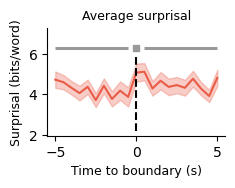

In [47]:
model, fig, ax = plot_boundary_comparison(
    plot_array=story_plot_arrays_surprisal2,
    xlabel='Time to boundary (s)',
    ylabel='Surprisal (bits/word)',
    title='Average surprisal',
    color = colors[0],
    savepath=None,  # os.path.join(save_dir, model_save_dir_name, 'ce_around_boundary', 'surprisal_by_time_sig_to_boundary.svg')
)

In [62]:
# calculate mean and standard error 
all_plot_arrays = []
for i,story in enumerate(story_big_dfs2.keys()):
    all_plot_arrays.append(story_plot_arrays_kl2[story])
all_plot_arrays = np.concatenate(all_plot_arrays)
nanmean = np.nanmean(all_plot_arrays,axis =0)
good_count = np.sum(~np.isnan(all_plot_arrays),axis = 0)
yerr = np.nanstd(all_plot_arrays,axis =0)/np.sqrt(good_count)
#yerr = np.nanstd(all_plot_arrays,axis =0)/np.sqrt(len(all_plot_arrays))

# fig,ax = plt.subplots(figsize = (2.3,1.5))
# xx=np.linspace(-bin_duration*num_bins,bin_duration*num_bins,num_bins*2+1)
# plt.plot(xx,nanmean,color = colors[4]) # the original color is too faint, so changed to this version
# plt.fill_between(xx, nanmean-yerr, nanmean+yerr,alpha=0.3,color = colors[4])
# plt.vlines(x=0,ymin=5,ymax = 14,linestyles='dashed',color='black')

# plt.xlabel('Time to boundary (s)',fontsize=fontsize)
# plt.ylabel('Relative entropy (bits/word)',fontsize=fontsize)
# plt.title('Average relative entropy',fontsize=fontsize)
# sns.despine()
#fig.savefig(os.path.join(save_dir,model_save_dir_name,'ce_around_boundary','kl_by_time.svg'),transparent = True)

boundary_bin = all_plot_arrays[:,num_bins]
pre_boundary = all_plot_arrays[:,:num_bins]
post_boundary = all_plot_arrays[:,num_bins+1:]
not_boundary = np.hstack([pre_boundary,post_boundary])
pre_boundary_mean = np.nanmean(pre_boundary,axis = 1)
post_boundary_mean = np.nanmean(post_boundary,axis =1)
res_pre_to_post = stats.ttest_rel(pre_boundary_mean,post_boundary_mean,nan_policy = 'omit')
pval_pre_to_post = res_pre_to_post.pvalue

print(res_pre_to_post)

TtestResult(statistic=np.float64(2.4653673361865627), pvalue=np.float64(0.01485424058493786), df=np.int64(145))


/tmp/ipykernel_2491777/877124780.py:57: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


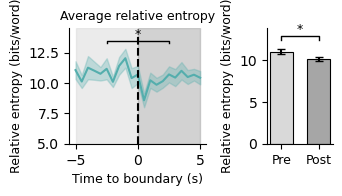

In [ ]:
pre_color  = "#D9D9D9"   # light gray (pre-boundary window)
post_color = "#A6A6A6"   # medium gray (post-boundary window)


fig = plt.figure(figsize=(3.4, 1.5))
gs = fig.add_gridspec(1, 2, width_ratios=[2.3, 1.1], wspace=0.6)
ax  = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])

# ---------- Panel 1: time course with shaded windows + bracket ----------
ax.axvspan(-bin_duration*num_bins, 0, color=pre_color, alpha=0.5, zorder=0)
ax.axvspan(0, bin_duration*num_bins, color=post_color, alpha=0.5, zorder=0)
xx=np.linspace(-bin_duration*num_bins,bin_duration*num_bins,num_bins*2+1)
ax.plot(xx, nanmean, color=colors[4])
ax.fill_between(xx, nanmean-yerr, nanmean+yerr, alpha=0.3, color=colors[4])
ax.vlines(x=0, ymin=5, ymax=14, linestyles='dashed', color='black')

y_bracket = 13.3
tick = 0.15
x1, x2 = -bin_duration*num_bins*0.5, bin_duration*num_bins*0.5
ax.plot([x1, x1, x2, x2],
        [y_bracket, y_bracket+tick, y_bracket+tick, y_bracket],
        color='black', linewidth=1)
ax.text((x1+x2)/2, y_bracket+tick, get_significance(pval_pre_to_post),
        ha='center', va='bottom', fontsize=fontsize)

ax.set_xlabel('Time to boundary (s)', fontsize=fontsize)
ax.set_ylabel('Relative entropy (bits/word)', fontsize=fontsize)
ax.set_title('Average relative entropy', fontsize=fontsize)
ax.set_ylim(5, 14.5)
sns.despine(ax=ax)

# ---------- Panel 2: bar plot of window means with SEM + bracket ----------
means = [np.nanmean(pre_boundary_mean), np.nanmean(post_boundary_mean)]
sems  = [np.nanstd(pre_boundary_mean, ddof=1)/np.sqrt(np.sum(~np.isnan(pre_boundary_mean))),
         np.nanstd(post_boundary_mean, ddof=1)/np.sqrt(np.sum(~np.isnan(post_boundary_mean)))]

xpos = [0, 1]
ax2.bar(xpos, means, yerr=sems, width=0.6, color=[pre_color, post_color],
        edgecolor='black', linewidth=0.8, capsize=3, zorder=2)

y_max = max(m+s for m, s in zip(means, sems))
y_bracket2 = y_max * 1.1
tick2 = y_max * 0.04
ax2.plot([0, 0, 1, 1],
         [y_bracket2, y_bracket2+tick2, y_bracket2+tick2, y_bracket2],
         color='black', linewidth=1)
ax2.text(0.5, y_bracket2+tick2, get_significance(pval_pre_to_post),
         ha='center', va='bottom', fontsize=fontsize)

ax2.set_xticks(xpos)
ax2.set_xticklabels(['Pre', 'Post'], fontsize=fontsize)
ax2.set_ylabel('Relative entropy (bits/word)', fontsize=fontsize)
ax2.set_ylim(0, y_bracket2 + tick2*3)
sns.despine(ax=ax2)

plt.tight_layout()
#fig.savefig(os.path.join(save_dir, model_save_dir_name, 'ce_around_boundary', 'kl_by_time_pre_post_with_bars.svg'), transparent=True)

## LME results in rebuttal letter

In [50]:
# comparing pre-boundary bins to boundary bin, and post-boundary bins to boundary bin, using linear mixed-effects model
import statsmodels.formula.api as smf
# test within 1s of boundary with lme, not significant
lme_df = make_lme_boundary_df(story_plot_arrays_surprisal2,num_bins,cutoff = 2)
lme_df_wide = lme_df.pivot(index='boundary_idx', columns=['condition'], values='value')
lme_df_wide_clean = lme_df_wide.dropna()
# boundary vs. post boundary 
lme_df_clean = lme_df_wide_clean.reset_index().melt(
    id_vars='boundary_idx',
    #value_vars=['boundary','pre', 'post'],
    value_vars=['boundary','post'],
    var_name='condition',
    value_name='value'
)

lme_df_clean['story'] = lme_df_clean['boundary_idx'].str.split('_').str[0]

# because boundary_idx is unique across stories (story_pair_idx), specifiying story level vc_formula actually doesn't change results
# see https://www.statsmodels.org/devel/examples/notebooks/generated/variance_components.html
model = smf.mixedlm(
    "value ~ condition",
    lme_df_clean,
    groups=lme_df_clean["boundary_idx"],           # repeated-measure unit (boundary)
   vc_formula={"story": "0 + C(story)"}   # random intercept per story
).fit(reml=True)
print('Boundary vs. Post Boundary (within 1s of boundary) LME Results')
print(model.summary())

# boundary vs pre boudnary
lme_df_clean_pre = lme_df_wide_clean.reset_index().melt(
    id_vars='boundary_idx',
    #value_vars=['boundary','pre', 'post'],
    value_vars=['boundary','pre'],
    var_name='condition',
    value_name='value'
)

lme_df_clean_pre['story'] = lme_df_clean_pre['boundary_idx'].str.split('_').str[0]

model_pre = smf.mixedlm(
    "value ~ condition",
    lme_df_clean_pre,
    groups=lme_df_clean_pre["boundary_idx"],           # repeated-measure unit (boundary)
   vc_formula={"story": "0 + C(story)"}   # random intercept per story
).fit(reml=True)
print('Boundary vs. Pre Boundary (within 1s of boundary) LME Results')
print(model_pre.summary())




Boundary vs. Post Boundary (within 1s of boundary) LME Results
           Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  value    
No. Observations:    110      Method:              REML     
No. Groups:          55       Scale:               12.3904  
Min. group size:     2        Log-Likelihood:      -298.2632
Max. group size:     2        Converged:           Yes      
Mean group size:     2.0                                    
------------------------------------------------------------
                  Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------
Intercept          5.216    0.499 10.459 0.000  4.238  6.193
condition[T.post] -0.356    0.671 -0.531 0.595 -1.672  0.959
story Var          1.287    0.579                           

Boundary vs. Pre Boundary (within 1s of boundary) LME Results
           Mixed Linear Model Regression Results
Model:              MixedLM  Dependent Varia

/tmp/ipykernel_2491777/3750234334.py:17: RuntimeWarning: Mean of empty slice
  pre_boundary_mean = np.nanmean(pre_boundary,axis = 1)
/tmp/ipykernel_2491777/3750234334.py:18: RuntimeWarning: Mean of empty slice
  post_boundary_mean = np.nanmean(post_boundary,axis =1)


In [51]:
# comparing pre-boundary bins, boundary bin, and post-boundary bins, using linear mixed-effects model
import statsmodels.formula.api as smf
# test within 1s of boundary with lme, not significant
lme_df = make_lme_boundary_df(story_plot_arrays_surprisal2,num_bins,cutoff = 2)
lme_df_wide = lme_df.pivot(index='boundary_idx', columns=['condition'], values='value')
lme_df_wide_clean = lme_df_wide.dropna()
lme_df_clean = lme_df_wide_clean.reset_index().melt(
    id_vars='boundary_idx',
    value_vars=['boundary','pre', 'post'],
    var_name='condition',
    value_name='value'
)

lme_df_clean['story'] = lme_df_clean['boundary_idx'].str.split('_').str[0]
lme_df_clean['boundary_idx'] = lme_df_clean['boundary_idx'].str.split('_').str[2]

model = smf.mixedlm(
    "value ~ condition",
    lme_df_clean,
    groups=lme_df_clean["boundary_idx"],           # repeated-measure unit (boundary)
    vc_formula={"story": "0 + C(story)"}   # random intercept per story
).fit(reml=True)
model.summary()

/tmp/ipykernel_2491777/3750234334.py:17: RuntimeWarning: Mean of empty slice
  pre_boundary_mean = np.nanmean(pre_boundary,axis = 1)
/tmp/ipykernel_2491777/3750234334.py:18: RuntimeWarning: Mean of empty slice
  post_boundary_mean = np.nanmean(post_boundary,axis =1)


<class 'statsmodels.iolib.summary2.Summary'>
"""
           Mixed Linear Model Regression Results
============================================================
Model:               MixedLM  Dependent Variable:  value    
No. Observations:    165      Method:              REML     
No. Groups:          26       Scale:               11.6625  
Min. group size:     3        Log-Likelihood:      -448.4437
Max. group size:     15       Converged:           Yes      
Mean group size:     6.3                                    
------------------------------------------------------------
                  Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------
Intercept          5.216    0.508 10.262 0.000  4.220  6.212
condition[T.post] -0.356    0.651 -0.547 0.584 -1.633  0.920
condition[T.pre]  -0.445    0.651 -0.684 0.494 -1.722  0.831
story Var          2.545    0.444                           
============================================================

"""

In [52]:
# comparing pre-boundary bins to boundary bin, and post-boundary bins to boundary bin, using linear mixed-effects model
import statsmodels.formula.api as smf
# test within 5s of boundary with lme, not significant
lme_df = make_lme_boundary_df(story_plot_arrays_surprisal2,num_bins,cutoff = 0)
lme_df_wide = lme_df.pivot(index='boundary_idx', columns=['condition'], values='value')
lme_df_wide_clean = lme_df_wide.dropna()
# boundary vs. post boundary 
lme_df_clean = lme_df_wide_clean.reset_index().melt(
    id_vars='boundary_idx',
    #value_vars=['boundary','pre', 'post'],
    value_vars=['boundary','post'],
    var_name='condition',
    value_name='value'
)

lme_df_clean['story'] = lme_df_clean['boundary_idx'].str.split('_').str[0]

model = smf.mixedlm(
    "value ~ condition",
    lme_df_clean,
    groups=lme_df_clean["boundary_idx"],           # repeated-measure unit (boundary)
   vc_formula={"story": "0 + C(story)"}   # random intercept per story
).fit(reml=True)
print('Boundary vs. Post Boundary (within 5s of boundary) LME Results')
print(model.summary())

# boundary vs pre boudnary
lme_df_clean_pre = lme_df_wide_clean.reset_index().melt(
    id_vars='boundary_idx',
    #value_vars=['boundary','pre', 'post'],
    value_vars=['boundary','pre'],
    var_name='condition',
    value_name='value'
)

lme_df_clean_pre['story'] = lme_df_clean_pre['boundary_idx'].str.split('_').str[0]

model_pre = smf.mixedlm(
    "value ~ condition",
    lme_df_clean_pre,
    groups=lme_df_clean_pre["boundary_idx"],           # repeated-measure unit (boundary)
   vc_formula={"story": "0 + C(story)"}   # random intercept per story
).fit(reml=True)
print('Boundary vs. Pre Boundary (within 5s of boundary) LME Results')
print(model_pre.summary())


p_post = model.pvalues['condition[T.post]']    # pre vs boundary
p_pre = model_pre.pvalues['condition[T.pre]']  # post vs boundary


# Optional: FDR correct across these two comparisons
pvals_corrected = multitest.multipletests(
    [p_pre, p_post],
    method='fdr_bh'
)[1]

sig_pre = get_significance(pvals_corrected[0])
sig_post = get_significance(pvals_corrected[1])

print('pre vs boundary:', p_pre, 'corrected:', pvals_corrected[0])
print('post vs boundary:', p_post, 'corrected:', pvals_corrected[1])


# pre-boundary vs post boudnary
lme_df_clean_pre_post = lme_df_wide_clean.reset_index().melt(
    id_vars='boundary_idx',
    #value_vars=['boundary','pre', 'post'],
    value_vars=['post','pre'],
    var_name='condition',
    value_name='value'
)

lme_df_clean_pre_post['story'] = lme_df_clean_pre_post['boundary_idx'].str.split('_').str[0]

model_pre_post = smf.mixedlm(
    "value ~ condition",
    lme_df_clean_pre_post,
    groups=lme_df_clean_pre_post["boundary_idx"],           # repeated-measure unit (boundary)
   vc_formula={"story": "0 + C(story)"}   # random intercept per story
).fit(reml=True)
print('Pre Boundary vs. Post Boundary (within 5s of boundary) LME Results')
print(model_pre_post.summary())


Boundary vs. Post Boundary (within 5s of boundary) LME Results
           Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  value    
No. Observations:    152      Method:              REML     
No. Groups:          76       Scale:               8.2050   
Min. group size:     2        Log-Likelihood:      -380.5725
Max. group size:     2        Converged:           Yes      
Mean group size:     2.0                                    
------------------------------------------------------------
                  Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------
Intercept          5.073    0.341 14.858 0.000  4.403  5.742
condition[T.post] -0.664    0.465 -1.428 0.153 -1.575  0.247
story Var          0.654    0.383                           

Boundary vs. Pre Boundary (within 5s of boundary) LME Results
           Mixed Linear Model Regression Results
Model:              MixedLM  Dependent Varia

In [53]:
lme_df_clean.groupby('condition')['value'].agg(['mean', 'std', 'count'])

,mean,std,count
condition,,,
boundary,5.072573,3.914538,76
post,4.408814,1.547241,76


In [54]:
# comparing pre-boundary bins, boundary bin, and post-boundary bins, using linear mixed-effects model
import statsmodels.formula.api as smf
# test within 5s of boundary with lme, significant difference between [-5,0) pre-boundary surprisal and surprisal at boundary (p=0.045), 
# but there is no significant between post-boundary surprisal and surprisal at boundary
lme_df = make_lme_boundary_df(story_plot_arrays_surprisal2,num_bins,cutoff = 0)
lme_df_wide = lme_df.pivot(index='boundary_idx', columns=['condition'], values='value')
lme_df_wide_clean = lme_df_wide.dropna()
lme_df_clean = lme_df_wide_clean.reset_index().melt(
    id_vars='boundary_idx',
    value_vars=['boundary','pre', 'post'],
    var_name='condition',
    value_name='value'
)

lme_df_clean['story'] = lme_df_clean['boundary_idx'].str.split('_').str[0]
lme_df_clean['boundary_idx'] = lme_df_clean['boundary_idx'].str.split('_').str[2]

model = smf.mixedlm(
    "value ~ condition",
    lme_df_clean,
    groups=lme_df_clean["boundary_idx"],           # repeated-measure unit (boundary)
    vc_formula={"story": "0 + C(story)"}   # random intercept per story
).fit(reml=True)
print(model.summary())

p_pre = model.pvalues['condition[T.pre]']    # pre vs boundary
p_post = model.pvalues['condition[T.post]']  # post vs boundary

# Optional: FDR correct across these two comparisons
pvals_corrected = multitest.multipletests(
    [p_pre, p_post],
    method='fdr_bh'
)[1]

sig_pre = get_significance(pvals_corrected[0])
sig_post = get_significance(pvals_corrected[1])

print('pre vs boundary:', p_pre, 'corrected:', pvals_corrected[0])
print('post vs boundary:', p_post, 'corrected:', pvals_corrected[1])

           Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  value    
No. Observations:    228      Method:              REML     
No. Groups:          26       Scale:               6.2258   
Min. group size:     3        Log-Likelihood:      -540.7651
Max. group size:     18       Converged:           Yes      
Mean group size:     8.8                                    
------------------------------------------------------------
                  Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------
Intercept          5.073    0.299 16.948 0.000  4.486  5.659
condition[T.post] -0.664    0.405 -1.640 0.101 -1.457  0.130
condition[T.pre]  -0.811    0.405 -2.003 0.045 -1.604 -0.017
story Var          0.583    0.213                           

pre vs boundary: 0.045196905798062105 corrected: 0.09039381159612421
post vs boundary: 0.101035760339048 corrected: 0.101035760339048


In [55]:
stats.ttest_rel(lme_df_wide_clean['pre'],lme_df_wide_clean['boundary'])

TtestResult(statistic=np.float64(-1.7318465560178042), pvalue=np.float64(0.08741214466356853), df=np.int64(75))

In [56]:
# LME comparing first bin, boundary bin, and last bin
lme_df_first_last = make_lme_boundary_df2(story_plot_arrays_surprisal2,num_bins)
lme_df_first_last_wide = lme_df_first_last.pivot(index='boundary_idx', columns=['condition'], values='value')
lme_df_first_last_wide_clean = lme_df_first_last_wide.dropna()
lme_df_first_last_clean = lme_df_first_last_wide_clean.reset_index().melt(
    id_vars='boundary_idx',
    value_vars=['boundary','first', 'last'],
    var_name='condition',
    value_name='value'
)

lme_df_first_last_clean['story'] = lme_df_first_last_clean['boundary_idx'].str.split('_').str[0]


model = smf.mixedlm(
    "value ~ condition",
    lme_df_first_last_clean,
    groups=lme_df_first_last_clean["boundary_idx"],           # repeated-measure unit (boundary)
    vc_formula={"story": "0 + C(story)"}   # random intercept per story
).fit(reml=True)
model.summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
            Mixed Linear Model Regression Results
=============================================================
Model:              MixedLM   Dependent Variable:   value    
No. Observations:   156       Method:               REML     
No. Groups:         52        Scale:                20.1155  
Min. group size:    3         Log-Likelihood:       -455.8932
Max. group size:    3         Converged:            Yes      
Mean group size:    3.0                                      
-------------------------------------------------------------
                   Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------------
Intercept           5.252    0.636  8.258 0.000  4.005  6.498
condition[T.first] -0.007    0.880 -0.008 0.994 -1.731  1.717
condition[T.last]  -0.099    0.880 -0.112 0.911 -1.823  1.625
story Var           0.913    0.412                           
=============================================================

"""

In [57]:
# LME comparing the first bin to the boundary bin, and the last bin to the boundary bin
lme_df_first_last = make_lme_boundary_df2(story_plot_arrays_surprisal2,num_bins)
lme_df_first_last_wide = lme_df_first_last.pivot(index='boundary_idx', columns=['condition'], values='value')
lme_df_first_last_wide_clean = lme_df_first_last_wide.dropna()
lme_df_first_to_boundary = lme_df_first_last_wide_clean.reset_index().melt(
    id_vars='boundary_idx',
    value_vars=['boundary','first'],
    var_name='condition',
    value_name='value'
)

lme_df_first_to_boundary['story'] = lme_df_first_to_boundary['boundary_idx'].str.split('_').str[0]


model_first_to_boundary = smf.mixedlm(
    "value ~ condition",
    lme_df_first_to_boundary,
    groups=lme_df_first_to_boundary["boundary_idx"],           # repeated-measure unit (boundary)
    vc_formula={"story": "0 + C(story)"}   # random intercept per story
).fit(reml=True)
print('First bin vs. Boundary bin LME Results')
print(model_first_to_boundary.summary())


lme_df_last_to_boundary = lme_df_first_last_wide_clean.reset_index().melt(
    id_vars='boundary_idx',
    value_vars=['boundary','last'],
    var_name='condition',
    value_name='value'
)

lme_df_last_to_boundary['story'] = lme_df_last_to_boundary['boundary_idx'].str.split('_').str[0]


model_last_to_boundary = smf.mixedlm(
    "value ~ condition",
    lme_df_last_to_boundary,
    groups=lme_df_last_to_boundary["boundary_idx"],           # repeated-measure unit (boundary)
    vc_formula={"story": "0 + C(story)"}   # random intercept per story
).fit(reml=True)
print('Last bin vs. Boundary bin LME Results')
print(model_last_to_boundary.summary())


First bin vs. Boundary bin LME Results
            Mixed Linear Model Regression Results
Model:              MixedLM   Dependent Variable:   value    
No. Observations:   104       Method:               REML     
No. Groups:         52        Scale:                20.1877  
Min. group size:    2         Log-Likelihood:       -301.9417
Max. group size:    2         Converged:            Yes      
Mean group size:    2.0                                      
-------------------------------------------------------------
                   Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------------
Intercept           5.252    0.623  8.429 0.000  4.030  6.473
condition[T.first] -0.007    0.881 -0.008 0.994 -1.734  1.720
story Var           0.000    0.658                           

Last bin vs. Boundary bin LME Results
           Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  value    
No. Observations: 

/home/jianing/miniconda3/envs/imaging/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/home/jianing/miniconda3/envs/imaging/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


## look at what happens around punctuation 

In [58]:
def find_word_indices_in_tokenized_txt(original_txt,tokenized_txt):
    '''
    input: original_txt (string, story transcript), tokenized_txt (list, tokenized by LM)
    output: list of lists, each sublist indicates the [start,end] (exclusive) indices or a word from the original_txt in the tokenized_txt'''
    start_idx_in_tokenized_txt = 0
    end_idx_in_tokenized_txt = 0
    curr_word = ''
    word_indices_in_tokenized_txt = []
    for w in original_txt.split(' '):
        while curr_word!=w and len(curr_word)<len(w):
            curr_word+=tokenized_txt[end_idx_in_tokenized_txt].translate(str.maketrans('', '', model_initial_char))
            end_idx_in_tokenized_txt+=1
        if curr_word==w:
            if curr_word =='':
                curr_word+=tokenized_txt[end_idx_in_tokenized_txt].translate(str.maketrans('', '', model_initial_char))
                assert curr_word==w
                end_idx_in_tokenized_txt+=1
            word_indices_in_tokenized_txt.append([start_idx_in_tokenized_txt,end_idx_in_tokenized_txt])
            start_idx_in_tokenized_txt=end_idx_in_tokenized_txt
            curr_word = ''
        else:
            print('%s not found'%w)
    return word_indices_in_tokenized_txt

In [59]:
# map where punctuation would've happen to original txt
punctuated_transcript_dir = os.path.join(behavior_data_dir,'transcripts','punctuated')
all_stories_punctuation_indices = {} # indices of word in original_txt.split(' ') that would have .!? right after
for story in stories:
    with open(os.path.join(punctuated_transcript_dir,'%s_punctuated.txt'%story),'r') as f:
        punctuated_txt = f.read()
    with open(os.path.join(original_transcript_dir,'%s.txt'%story),'r') as f:
        original_txt = f.read()
    timing_df = pd.read_csv(os.path.join(timing_dir,'%s_timing.csv'%story))
    punctuated_txt_split = re.split(r"[ -]+",punctuated_txt)
    original_txt_split = re.split(r"[ -]+",original_txt)
    #print(len(punctuated_txt_split),len(original_txt_split))
    # first make sure these punctuated and original transcripts are aligned
    assert len(punctuated_txt_split)==len(original_txt_split),'word split of punctuated and original txt must have the same length'
    strip_chars = string.punctuation + '-–“”’'
    for i in range(len(punctuated_txt_split)):
        punc_word = punctuated_txt_split[i]
        original_word = original_txt_split[i]
        punc_word_strip = punc_word.lower().translate(str.maketrans('', '', strip_chars))
        original_word_strip = original_word.lower().translate(str.maketrans('', '', strip_chars))
        if punc_word_strip!=original_word_strip:
            print('word between punctuated vs. original is not the same:',story,i,punc_word,original_word)
    # but the split from re ignores double spaces, so in those cases the re split will be shorter than original_txt.split(' ') which is used to compute the consensus_txt
    # so let's align the re splits to the original_txt.split(' ')
    if len(original_txt.split(' '))!=len(original_txt_split):
        empty_string_indices = [i for i,w in enumerate(original_txt.split(' ')) if w=='']
        for i in empty_string_indices:
            original_txt_split.insert(i,'')
            punctuated_txt_split.insert(i,'')
        assert original_txt_split==original_txt.split(' '),'two splits must be the same after insertion'
    punctuation_indices = np.array([i for i,w in enumerate(punctuated_txt_split) if any(c in w for c in ".!?")])
    all_stories_punctuation_indices[story] = punctuation_indices

In [60]:
bin_duration = 0.5 #s
seconds = 5
num_bins = int(seconds/bin_duration) # on each side 
include_if_midpoint = True

story_plot_arrays_info_rate_punc = {}
story_plot_arrays_speech_rate_punc = {}
story_plot_arrays_surprisal_punc = {}
story_plot_arrays_kl_punc = {}
for story in stories:
    
    with open(os.path.join(moth_output_dir,story,'cross_entropy.pkl'),'rb') as f:
        original_ce = pickle.load(f)
    story_kl = np.load(os.path.join(moth_output_dir,story,'kl.npy'))
    story_kl = story_kl[:-1] 
    story_kl = np.insert(story_kl,0,np.nan)
    # tokenized txt 
    with open(os.path.join(moth_output_dir,story,'tokenized_txt.pkl'),'rb') as f:
        tokenized_txt = pickle.load(f)
    timing_df = pd.read_csv(os.path.join(timing_dir,'%s_timing.csv'%story))
    if story=='pieman':
        timing_df['start'] = timing_df['start']/1000
        timing_df['stop'] = timing_df['stop']/1000
    with open(os.path.join(original_transcript_dir,'%s.txt'%story),'r') as f:
        original_txt = f.read()
    punctuation_indices = all_stories_punctuation_indices[story] # indices in original_txt.split(' ')
    punctuation_indices = punctuation_indices[:-1] # don't include the one at the end of story
    
    # make timing_df as long as original_txt.split(' ') (should only matter for souls which is missing 2 '')
    # this way we can go from index in timing_df to tokens using word_indices_in_tokenized_txt
    if len(timing_df) != len(original_txt.split(' ')):
        empty_string_idx = []
        for i in range(len(original_txt.split(' '))):
            if original_txt.split(' ')[i] =='':
                #print(i)
                empty_string_idx.append(i)
        for idx in empty_string_idx:
            row = pd.DataFrame({"text": '', "start": np.nan,"stop":np.nan}, index=[idx])
            timing_df = pd.concat([timing_df.iloc[:idx], row, timing_df.iloc[idx:]]).reset_index(drop=True)
    if story =='souls':
        timing_df['text'] = [t[:-1] if t!= '' and t[-1] == ' ' else t for t in timing_df['text']]
    assert len(original_txt.split(' '))==len(timing_df)
    timing_word_list = [t if isinstance(t,str) else '' for t in list(timing_df['text'].values)]
    timing_word_list_low = [x.lower() for x in timing_word_list]
    assert ' '.join(timing_word_list).lower() == original_txt
    
    # [start,stop] indices of each word in tokenized_txt
    word_indices_in_tokenized_txt = find_word_indices_in_tokenized_txt(original_txt,tokenized_txt)
    
    plot_arrays_info_rate = np.ones((len(punctuation_indices),num_bins*2+1))*np.nan
    plot_arrays_speech_rate = np.ones((len(punctuation_indices),num_bins*2+1))*np.nan
    plot_arrays_surprisal = np.ones((len(punctuation_indices),num_bins*2+1))*np.nan
    plot_arrays_kl = np.ones((len(punctuation_indices),num_bins*2+1))*np.nan
    for i,punc_idx in enumerate(punctuation_indices):
        # find time when punctutation happened
        punc_time = (timing_df['stop'].iloc[punc_idx]+timing_df['start'].iloc[punc_idx+1])/2 # midpoint between end of last word in sentence and start of the next, this will be the center of the middle bin

        # the end of the middle bin is the segmentation time
        range_start = punc_time-(num_bins+1)*bin_duration
        range_end = punc_time+(num_bins)*bin_duration
        bin_edges = np.linspace(range_start,range_end,num_bins*2+1+1) # num_bins*2+1+1 because linspace gives that many numbers, and we need num_bins*2+1 intervals
        # if an edge is smaller than story start time or later than story end time, throw out the bin 
        bin_edges = [edge if edge>=timing_df['start'].iloc[0] and edge<=timing_df['stop'].iloc[len(timing_df)-1] else np.nan for edge in bin_edges]
        bin_edges_start = bin_edges[:-1]
        bin_edges_end = bin_edges[1:]
        
        word_mid_point = (timing_df['stop']+timing_df['start'].values)/2
        # each bin centered around a punctuation  
        for bin_idx,(bin_start,bin_end) in enumerate(zip(bin_edges_start,bin_edges_end)):
            word_indices_in_bin=[]
            if np.isnan(bin_start) or np.isnan(bin_end):
                continue
            if include_if_midpoint:
                word_indices_in_bin = [idx for idx,timing in enumerate(word_mid_point) if timing>=bin_start and timing<=bin_end]
            else:
                for row_idx,row in timing_df.iterrows():
                    if row['start']<bin_start and row['stop']>bin_start:
                        word_indices_in_bin.append(row_idx)
                    elif row['start']<bin_end and row['stop']>bin_end:
                        word_indices_in_bin.append(row_idx)
                    elif row['start']>bin_start and row['stop']<bin_end:
                        word_indices_in_bin.append(row_idx)
            #print(word_indices_in_bin)
            # CE and KL for each word in bin (sum of the measure for all tokens within a word)
            word_ce_in_bin = []
            word_kl_in_bin = []
            for idx in word_indices_in_bin:
                start_word_index_intokens = word_indices_in_tokenized_txt[idx][0]
                end_word_index_intokens = word_indices_in_tokenized_txt[idx][1]
                word_ce_in_bin.append(torch.sum(original_ce[start_word_index_intokens:end_word_index_intokens]).numpy())
                word_kl_in_bin.append(np.sum(story_kl[start_word_index_intokens:end_word_index_intokens]))
            word_ce_in_bin = np.array(word_ce_in_bin)
            word_kl_in_bin = np.array(word_kl_in_bin)
            #print(word_kl_in_bin)

            speech_rate = len(word_indices_in_bin)/bin_duration
            bin_ce = np.sum(word_ce_in_bin)
            info_rate = bin_ce/bin_duration
            surprisal = np.mean(word_ce_in_bin) # when there are no words in this bin, surprisal and kl will be nan
            kl = np.mean(word_kl_in_bin)
            plot_arrays_speech_rate[i,bin_idx]=speech_rate
            plot_arrays_info_rate[i,bin_idx] = info_rate
            plot_arrays_surprisal[i,bin_idx] = surprisal
            plot_arrays_kl[i,bin_idx] = kl
            
    story_plot_arrays_info_rate_punc[story] = plot_arrays_info_rate
    story_plot_arrays_speech_rate_punc[story] = plot_arrays_speech_rate
    story_plot_arrays_surprisal_punc[story] = plot_arrays_surprisal
    story_plot_arrays_kl_punc[story] = plot_arrays_kl

/home/jianing/miniconda3/envs/imaging/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/jianing/miniconda3/envs/imaging/lib/python3.11/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/jianing/miniconda3/envs/imaging/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/jianing/miniconda3/envs/imaging/lib/python3.11/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/jianing/miniconda3/envs/imaging/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/jianing/miniconda3/envs/imaging/lib/python3.11

TtestResult(statistic=np.float64(2.727035188307346), pvalue=np.float64(0.006568561410645195), df=np.int64(630))


/tmp/ipykernel_2491777/3529293360.py:76: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


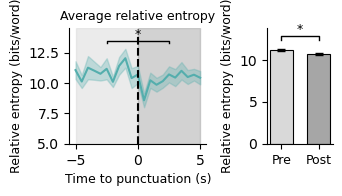

In [61]:
all_plot_arrays = []
for i,story in enumerate(stories):
    all_plot_arrays.append(story_plot_arrays_kl_punc[story])
all_plot_arrays = np.concatenate(all_plot_arrays)

boundary_bin = all_plot_arrays[:,num_bins]
pre_boundary = all_plot_arrays[:,:num_bins]
post_boundary = all_plot_arrays[:,num_bins+1:]
not_boundary = np.hstack([pre_boundary,post_boundary])
pre_boundary_mean = np.nanmean(pre_boundary,axis = 1)
post_boundary_mean = np.nanmean(post_boundary,axis =1)
not_boundary_mean = np.nanmean(not_boundary,axis = 1)
# res_to_rest = stats.ttest_rel(boundary_bin,not_boundary_mean,nan_policy = 'omit')
# res_to_pre = stats.ttest_rel(boundary_bin,pre_boundary_mean,nan_policy = 'omit')
# res_to_post = stats.ttest_rel(boundary_bin,post_boundary_mean,nan_policy = 'omit')
res_pre_to_post = stats.ttest_rel(pre_boundary_mean,post_boundary_mean,nan_policy = 'omit')
#print(res_to_rest,res_to_pre,res_to_post)
print(res_pre_to_post)

pre_color  = "#D9D9D9"   # light gray (pre-boundary window)
post_color = "#A6A6A6"   # medium gray (post-boundary window)


fig = plt.figure(figsize=(3.4, 1.5))
gs = fig.add_gridspec(1, 2, width_ratios=[2.3, 1.1], wspace=0.6)
ax  = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])

# ---------- Panel 1: time course with shaded windows + bracket ----------
ax.axvspan(-bin_duration*num_bins, 0, color=pre_color, alpha=0.5, zorder=0)
ax.axvspan(0, bin_duration*num_bins, color=post_color, alpha=0.5, zorder=0)

ax.plot(xx, nanmean, color=colors[4])
ax.fill_between(xx, nanmean-yerr, nanmean+yerr, alpha=0.3, color=colors[4])
ax.vlines(x=0, ymin=5, ymax=14, linestyles='dashed', color='black')

y_bracket = 13.3
tick = 0.15
x1, x2 = -bin_duration*num_bins*0.5, bin_duration*num_bins*0.5
ax.plot([x1, x1, x2, x2],
        [y_bracket, y_bracket+tick, y_bracket+tick, y_bracket],
        color='black', linewidth=1)
ax.text((x1+x2)/2, y_bracket+tick, get_significance(pval_pre_to_post),
        ha='center', va='bottom', fontsize=fontsize)

ax.set_xlabel('Time to punctuation (s)', fontsize=fontsize)
ax.set_ylabel('Relative entropy (bits/word)', fontsize=fontsize)
ax.set_title('Average relative entropy', fontsize=fontsize)
ax.set_ylim(5, 14.5)
sns.despine(ax=ax)

# ---------- Panel 2: bar plot of window means with SEM + bracket ----------
means = [np.nanmean(pre_boundary_mean), np.nanmean(post_boundary_mean)]
sems  = [np.nanstd(pre_boundary_mean, ddof=1)/np.sqrt(np.sum(~np.isnan(pre_boundary_mean))),
         np.nanstd(post_boundary_mean, ddof=1)/np.sqrt(np.sum(~np.isnan(post_boundary_mean)))]

xpos = [0, 1]
ax2.bar(xpos, means, yerr=sems, width=0.6, color=[pre_color, post_color],
        edgecolor='black', linewidth=0.8, capsize=3, zorder=2)

y_max = max(m+s for m, s in zip(means, sems))
y_bracket2 = y_max * 1.1
tick2 = y_max * 0.04
ax2.plot([0, 0, 1, 1],
         [y_bracket2, y_bracket2+tick2, y_bracket2+tick2, y_bracket2],
         color='black', linewidth=1)
ax2.text(0.5, y_bracket2+tick2, get_significance(pval_pre_to_post),
         ha='center', va='bottom', fontsize=fontsize)

ax2.set_xticks(xpos)
ax2.set_xticklabels(['Pre', 'Post'], fontsize=fontsize)
ax2.set_ylabel('Relative entropy (bits/word)', fontsize=fontsize)
ax2.set_ylim(0, y_bracket2 + tick2*3)
sns.despine(ax=ax2)

plt.tight_layout()
#fig.savefig(os.path.join(save_dir, model_save_dir_name, 'ce_around_boundary', 'kl_by_time_pre_post_with_bars_punctuation.svg'), transparent=True)